<a href="https://colab.research.google.com/github/berdakh/ROBT407-SVM-Labs/blob/main/student/201_linear_svm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/berdakh/ROBT407-SVM-Labs/blob/main/student/201_linear_svm.ipynb)

# ROBT 407 · Linear SVMs: geometry, scaling, and the primal problem

**Student workbook | Python 3 | Core: 90 minutes | Deepening work + mini-project: 2–3 hours**

Distinguish functional and geometric margins; implement point-to-hyperplane distance; solve the hard-margin primal; explain why zero training error alone does not select a separator.

Use the cycle **predict → run → inspect → explain**. Write predictions before running experiments. Complete the TODO functions and rerun their checks. Synthetic experiments and bundled scikit-learn datasets are available locally; no dataset downloads are needed. Core activities follow the lecture; deepening labs and mini-projects extend it.

## Lecture alignment and course context
Source: **201_Linear-SVMs (2).pdf**. PDF pages 3–9: large-margin intuition; 10–27: distance, scaling and optimization; 28–32: four-point example and QP; 33–36: generalization. Page numbers refer to physical PDF pages, starting at 1, rather than the slide footer.

Course context: ROBT 407, Fall 2026; these activities support theoretical reasoning (CLO1), pipeline design and evaluation (CLO2), and Python implementation (CLO3). Textbook context: *Learning From Data*, Yaser S. Abu-Mostafa, Malik Magdon-Ismail, Hsuan-Tien Lin. No textbook excerpt was supplied; these are original explanations and exercises based on the uploaded slides, with no claimed textbook page mapping.

The lecture-specific quiz checks understanding of slide examples; it does not verify whether someone watched a video.

**Notation:** rows are examples; labels are −1 and +1 unless stated otherwise. Bias is separate from w. Margin means one-sided geometric margin unless explicitly called full width.

## Setup
Run cells in order in JupyterLab, Jupyter Notebook, or Google Colab with a Python 3 kernel. Required packages: NumPy, SciPy, Matplotlib, scikit-learn; ipywidgets is optional. Static plots and editable function calls remain available without widgets. Live sliders are opt-in: set ENABLE_WIDGETS=True in Setup and rerun an experiment cell. Static figures are the default for predictable batch execution. Student notebooks intentionally leave implementations incomplete; their checks print reminders until completed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.svm import SVC
from sklearn.datasets import make_moons, make_circles
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix
from IPython.display import display
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (7, 5), 'axes.grid': True, 'font.size': 11})
SEED = 407

def boundary(model, X, y, title='', ax=None):
    if ax is None: _, ax = plt.subplots()
    low, high = X.min(axis=0)-.6, X.max(axis=0)+.6
    xx, yy = np.meshgrid(np.linspace(low[0],high[0],160), np.linspace(low[1],high[1],160))
    zz = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=[-np.inf,0,np.inf], colors=['#e7edff','#ffe9da'], alpha=.8)
    ax.contour(xx, yy, zz, levels=[-1,0,1], colors='black', linestyles=['--','-','--'])
    ax.scatter(X[:,0],X[:,1],c=y,cmap='coolwarm',edgecolors='black',s=35)
    if hasattr(model,'support_'):
        sv = X[model.support_]
        ax.scatter(sv[:,0],sv[:,1],s=115,facecolors='none',edgecolors='#208050',linewidths=1.5,label='Support vectors')
        ax.legend(loc='best')
    ax.set(xlabel='$x_1$',ylabel='$x_2$',title=title)
    return ax

ENABLE_WIDGETS = False  # Set True and rerun the experiment cells for live sliders.

def optional_slider(fn, name, lo, hi, value, step):
    if not ENABLE_WIDGETS:
        print("To enable live sliders, set ENABLE_WIDGETS = True in Setup; direct function calls also work.")
        return
    # Static experiments remain available if this frontend cannot display widgets.
    try:
        import ipywidgets as widgets
        display(widgets.interactive(fn, **{name: widgets.FloatSlider(min=lo,max=hi,value=value,step=step,continuous_update=False)}))
    except ImportError:
        print('Widgets unavailable; call the experiment function with a new value.')

## 1. Theory: what does a large margin mean? (10 min)
For $x_n\in\mathbb R^d$, $y_n\in\{-1,+1\}$, weights $w\ne0$ and bias $b$,
$$f(x)=w^Tx+b,\qquad g(x)=\operatorname{sign}(f(x)).$$
The normal vector $w$ is perpendicular to the boundary $f(x)=0$. Projection onto its unit normal gives
$$d(x,H)=\frac{|w^Tx+b|}{\|w\|_2},\qquad
r_n=y_nf(x_n),\qquad \rho_n=\frac{r_n}{\|w\|_2}.$$
Here $r_n$ is the **functional margin**; $\rho_n$ is the **signed geometric margin**. A negative signed margin indicates an incorrect classification. Unsigned distance alone cannot tell whether a label is correct.

**Predict before running:** if both $w$ and $b$ are multiplied by 3, which quantities change? What if the multiplier is negative?

In [2]:
# Exact four-point example from the linear-SVM lecture.
X = np.array([[0.,0.],[2.,2.],[2.,0.],[3.,0.]])
y = np.array([-1.,-1.,1.,1.])

w0,b0 = np.array([1.,-1.]),-1.
for scale in [1.,3.,-2.]:
    w,b = scale*w0,scale*b0
    functional = y*(X@w+b)
    print('scale:',scale,'functional:',functional,'signed geometric:',functional/np.linalg.norm(w))

scale: 1.0 functional: [1. 1. 1. 2.] signed geometric: [0.70711 0.70711 0.70711 1.41421]
scale: 3.0 functional: [3. 3. 3. 6.] signed geometric: [0.70711 0.70711 0.70711 1.41421]
scale: -2.0 functional: [-2. -2. -2. -4.] signed geometric: [-0.70711 -0.70711 -0.70711 -1.41421]


### Implement A: distances (10 min)
Implement a vectorized function returning all unsigned distances. Reject a zero normal. Verify the known distances and then test a negative rescaling. Explain why negative scaling preserves the boundary but reverses predictions.

In [3]:
def distances(X, w, b):
    # TODO: return one unsigned distance per row of X.
    return None

In [4]:
result = distances(X,w0,b0)
if result is None:
    print('Complete Implement A, then rerun this check.')
else:
    np.testing.assert_allclose(result, np.array([1,1,1,2])/np.sqrt(2))
    np.testing.assert_allclose(result, distances(X,-2*w0,-2*b0))
    try: distances(X,np.zeros(2),0)
    except ValueError: pass
    else: raise AssertionError('Reject a zero normal')
    print('Distance checks passed.')

Complete Implement A, then rerun this check.


**Your reasoning:** write your prediction, observations and explanation here.

## 2. Canonical scaling and the primal (10 min)
For a correctly separating hyperplane let $s=\min_n y_nf(x_n)>0$. Dividing **both** $w$ and $b$ by $s$ makes the smallest functional margin equal to 1 without changing geometric distances.
$$\min_{w,b}\frac12 w^Tw\quad\text{subject to }y_n(w^Tx_n+b)\ge1\ \forall n.$$
At the optimum the one-sided geometric margin is $1/\|w\|$; the width between the two margin planes is $2/\|w\|$.

**Important distinction:** $1/\|w\|$ equals the closest-point distance when the canonical minimum functional margin is 1. Arbitrary rescaling does not change the actual geometric margin. Canonical rescaling only finds the best scale for a fixed boundary; optimizing also chooses its orientation and position. The bias is not penalized.

w, b, objective: [ 1. -1.] -0.9999999999999993 1.0000000000000009
functional margins: [1. 1. 1. 2.]
one-sided margin: 0.7071067811865472 full width: 1.4142135623730945


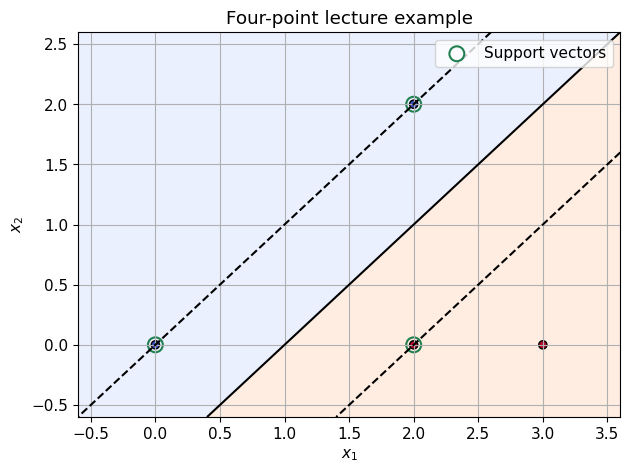

SVC is soft-margin; large C agrees here, but is not a hard-margin solver in general.


In [5]:
def solve_primal(X, y):
    d = X.shape[1]
    objective = lambda u: .5 * (u[:d] @ u[:d])
    gradient = lambda u: np.r_[u[:d], 0.]
    A = y[:,None]*np.c_[X,np.ones(len(X))]
    result = minimize(objective, np.zeros(d+1), jac=gradient,
        constraints={'type':'ineq','fun':lambda u:A@u-1,'jac':lambda u:A},
        method='SLSQP',options={'ftol':1e-11,'maxiter':2000})
    if not result.success: raise RuntimeError(result.message)
    w,b = result.x[:d],result.x[d]
    if np.min(y*(X@w+b)) < 1-1e-6: raise RuntimeError('Primal constraints failed')
    return w,b,result.fun

w,b,primal = solve_primal(X,y)
print('w, b, objective:',w,b,primal)
print('functional margins:',y*(X@w+b))
print('one-sided margin:',1/np.linalg.norm(w),'full width:',2/np.linalg.norm(w))
model = SVC(kernel='linear',C=1000,tol=1e-9).fit(X,y)
boundary(model,X,y,'Four-point lecture example');plt.show()
print('SVC is soft-margin; large C agrees here, but is not a hard-margin solver in general.')

### Implement B: canonical normalization (10 min)
Return canonically scaled $(w,b)$ for a strictly separating model. Reject nonseparating inputs. Check that the boundary and geometric margins remain unchanged.

In [6]:
def canonical_scale(X,y,w,b):
    # TODO: calculate the minimum functional margin, validate, then scale.
    return None

In [7]:
scaled = canonical_scale(X,y,3*w0,3*b0)
if scaled is None: print('Complete Implement B, then rerun.')
else:
    ws,bs = scaled
    np.testing.assert_allclose(np.min(y*(X@ws+bs)),1.)
    np.testing.assert_allclose(y*(X@ws+bs)/np.linalg.norm(ws),y*(X@w0+b0)/np.linalg.norm(w0))
    try: canonical_scale(X,y,-w0,-b0)
    except ValueError: pass
    else: raise AssertionError('Reject a nonseparating model')
    print('Canonical scaling checks passed.')

Complete Implement B, then rerun.


**Your reasoning:** write your prediction, observations and explanation here.

## 3. Move a point and observe (10 min)
Predict the boundary change as the positive point at (2, 0) moves toward the negative points. Record the margin and which points support it at three positions. The slider uses a high-C soft-margin implementation; the four-point geometry remains separable in this range.

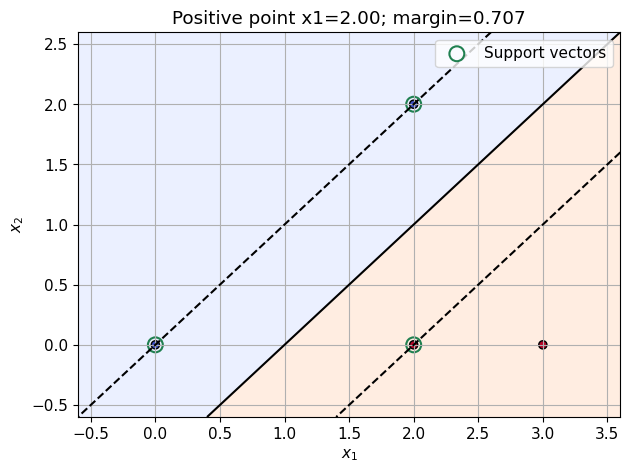

To enable live sliders, set ENABLE_WIDGETS = True in Setup; direct function calls also work.


In [8]:
def move_point(x_position=2.):
    Xm = X.copy(); Xm[2,0] = x_position
    m = SVC(kernel='linear',C=1000,tol=1e-8).fit(Xm,y)
    boundary(m,Xm,y,f'Positive point x1={x_position:.2f}; margin={1/np.linalg.norm(m.coef_):.3f}')
    plt.show()
move_point(2.)
optional_slider(move_point,'x_position',.3,2.8,2.,.1)

## 4. Explain the evidence (10 min)
1. For the lecture data, show by hand that $w=(1,-1)$, $b=-1$ is feasible and its objective is 1.
2. Compare two separators with zero training error. Why can their robustness to input perturbations differ?
3. Move the fourth point farther right and refit. Why might the optimum remain unchanged?
4. Is a larger training margin a guarantee of better test accuracy? Explain the roles of scaling, data distribution and model selection.

**Submit:** your completed functions, three experiment observations, and a short explanation connecting the margin to robustness. Large-margin reasoning depends on the feature geometry and data assumptions; it is not a universal test-accuracy guarantee.

## Deepening lab A · Derive a robustness certificate (15 min)
For an input perturbation $\delta$, Cauchy–Schwarz gives
$$y f(x+\delta)=y f(x)+y w^T\delta\ge y f(x)-\|w\|_2\|\delta\|_2.$$
If a correctly classified point has signed geometric margin $\rho=yf(x)/\|w\|$, every perturbation with $\|\delta\|_2<\rho$ preserves its predicted label. The strict inequality excludes a possible tie at the boundary. A tight perturbation towards the hyperplane is
$$\delta_*=-\frac{f(x)}{\|w\|^2}w.$$
**Derive:** show that $f(x+\delta_*)=0$ and $\|\delta_*\|=|f(x)|/\|w\|$. Why does the bias disappear from the perturbation term? This is a local statement for a fixed linear classifier, not a certificate for arbitrary nonlinear input transformations.

### Implement C · Closest boundary perturbation
Return the perturbation for every row of X. Reject a zero normal. Explain how this differs from adding random Gaussian noise.

In [9]:
def closest_boundary_step(X,w,b):
    # TODO: shape (N,d), pointing from each example to the boundary.
    return None

In [10]:
step=closest_boundary_step(X,w0,b0)
if step is None: print('Complete Implement C.')
else:
    np.testing.assert_allclose((X+step)@w0+b0,0,atol=1e-12)
    np.testing.assert_allclose(np.linalg.norm(step,axis=1),np.abs(X@w0+b0)/np.linalg.norm(w0))
    assert np.all(y*((X+.99*step)@w0+b0)>0)
    assert np.all(y*((X+1.01*step)@w0+b0)<0)
    print('Boundary and tightness checks passed.')

Complete Implement C.


**Your reasoning:** write your prediction, observations and explanation here.

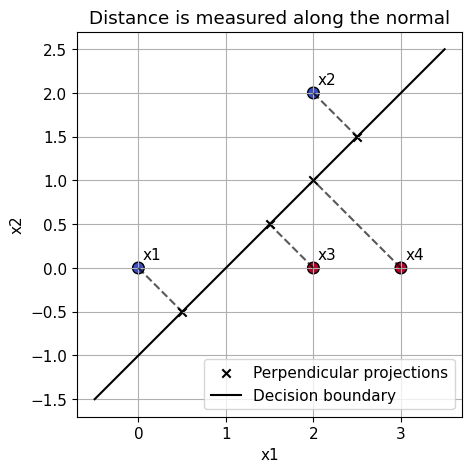

In [11]:
# Visualize the normal direction and perpendicular projections.
fig,ax=plt.subplots()
ax.scatter(X[:,0],X[:,1],c=y,cmap='coolwarm',s=70,edgecolors='black')
projections=X-(X@w0+b0)[:,None]*w0[None,:]/(w0@w0)
for i,(point,projection) in enumerate(zip(X,projections)):
    ax.plot([point[0],projection[0]],[point[1],projection[1]],'k--',alpha=.65)
    ax.annotate(f'x{i+1}',point+np.array([.05,.1]))
ax.scatter(projections[:,0],projections[:,1],marker='x',c='black',label='Perpendicular projections')
t=np.linspace(-.5,3.5,100)
ax.plot(t,t-1,c='black',label='Decision boundary')
ax.set(xlabel='x1',ylabel='x2',title='Distance is measured along the normal',aspect='equal')
ax.legend();plt.show()

## Deepening lab B · Why small norm is a constrained optimum (15 min)
Fix $b=-1$ for the four-point example. Its constraints imply $w_1\ge1$, $w_1+w_2\le0$, and $w_1\ge2/3$. The last is redundant. The closest feasible point to the origin is $(1,-1)$.

Sketch the feasible region before running the contour plot. Then distinguish this fixed-bias illustration from optimization over all $(w,b)$: it visualizes one slice of the original problem.

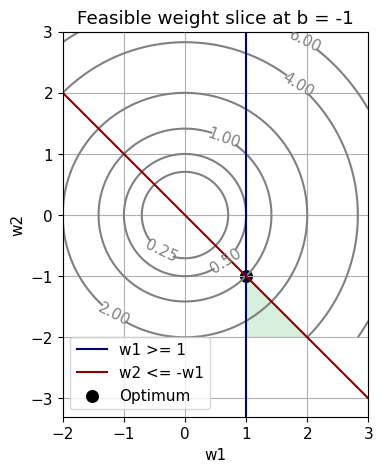

In [12]:
grid=np.linspace(-2,3,200);W1,W2=np.meshgrid(grid,grid)
feasible=(W1>=1)&(W1+W2<=0)&(W1>=2/3)
fig,ax=plt.subplots();ax.contourf(W1,W2,feasible,levels=[.5,1.5],colors=['#d6f0dc'])
cs=ax.contour(W1,W2,.5*(W1**2+W2**2),levels=[.25,.5,1,2,4,6],colors='gray')
ax.clabel(cs);ax.axvline(1,color='navy',label='w1 >= 1');ax.plot(grid,-grid,color='darkred',label='w2 <= -w1')
ax.scatter([1],[-1],c='black',s=70,label='Optimum')
ax.set(xlabel='w1',ylabel='w2',title='Feasible weight slice at b = -1',aspect='equal');ax.legend();plt.show()

### Implement D · Perceptron baseline from scratch
Train a perceptron with separate bias on separable data. Update only on nonpositive signed scores. Return w, b and mistakes per epoch. This optimizer seeks a separator rather than the largest-margin separator; compare the resulting geometric margin.

In [13]:
def train_perceptron(X,y,max_epochs=500):
    # TODO: start at zero, make online updates, stop after a mistake-free epoch.
    return None

In [14]:
pla=train_perceptron(X,y)
if pla is None: print('Complete Implement D.')
else:
    wpla,bpla,mistakes=pla
    assert np.all(y*(X@wpla+bpla)>0)
    print('PLA w,b:',wpla,bpla,'minimum geometric margin:',np.min(y*(X@wpla+bpla))/np.linalg.norm(wpla))
    print('SVM minimum geometric margin:',1/np.sqrt(2))
    plt.plot(mistakes,marker='o');plt.xlabel('Epoch');plt.ylabel('Mistakes');plt.title('Perceptron training trace');plt.show()

Complete Implement D.


**Your reasoning:** write your prediction, observations and explanation here.

### Implement E · Measure noise sensitivity
Estimate the error after independent isotropic Gaussian perturbations of each input. Average over all points and repetitions. Keep the classifier fixed; this is a robustness experiment, not a retraining experiment.

In [15]:
def noisy_error(X,y,w,b,sigma,repetitions=3000,seed=407):
    # TODO: perturb inputs, predict, and return a scalar fraction of errors.
    return None

In [16]:
baseline=noisy_error(X,y,w0,b0,0)
if baseline is None: print('Complete Implement E.')
else:
    assert baseline==0
    sigmas=np.linspace(0,1.5,12)
    errors=[noisy_error(X,y,w0,b0,s) for s in sigmas]
    assert all(0<=e<=1 for e in errors)
    from scipy.special import ndtr
    rho=y*(X@w0+b0)/np.linalg.norm(w0)
    expected=np.array([0 if s==0 else np.mean(ndtr(-rho/s)) for s in sigmas])
    plt.plot(sigmas,errors,'o',label='Monte Carlo');plt.plot(sigmas,expected,label='Gaussian projection formula')
    plt.xlabel('Noise standard deviation');plt.ylabel('Error probability');plt.title('Link geometric distance to robustness');plt.legend();plt.show()
    assert np.max(np.abs(np.asarray(errors)-expected))<.04

Complete Implement E.


**Your reasoning:** write your prediction, observations and explanation here.

## Real-data mini-project · Iris species classification (45–75 min)
150 observations, four measurements and three species.

**Before fitting:** write a hypothesis about the useful kernel or regularization strength, the expected errors and the effect of scaling.

**Search budget:** Tune one numerical hyperparameter, C: 5 candidates, 25 fold fits and one refit. Kernel family is fixed.

Use a stratified 80/20 development/test split. Hyperparameter selection uses **five-fold stratified cross-validation** on development data only. Fit scaling inside each fold through a pipeline. Reserve test labels until selection and refitting are finished. These datasets are bundled with scikit-learn; the loaders need no dataset download. Small benchmark results demonstrate a workflow rather than establish deployment performance.

### Understand the model-selection choices
| Choice | Effect | Applicable kernels |
|---|---|---|
| $C>0$ | Penalty per unit margin violation in the sum-loss objective | Linear, polynomial, RBF |
| $\gamma>0$ | Input scale in similarities | Polynomial, RBF |
| degree | Polynomial power | Polynomial |
| coef0 | Additive polynomial constant | Polynomial |
| kernel | Similarity family and feature geometry | Family comparison |

Distinguish hyperparameter **names**, candidate **values** per name, model **combinations** and total fold **fits**. Conditional grids add branch workloads instead of multiplying irrelevant parameters into every family. Five CV training/validation rotations are performed for each candidate; the winner is refitted on all development data.

SVC handles multiclass tasks using pairwise classifiers. Its packed multiclass coefficient array is not the single binary alpha vector used in earlier derivations.

In [17]:
from sklearn.datasets import load_iris
from sklearn.model_selection import ParameterGrid, cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, balanced_accuracy_score
import pandas as pd
project_data=load_iris()
project_X=project_data.data.copy();project_y=project_data.target.copy()
project_names=np.asarray(project_data.target_names).astype(str)

X_develop,X_holdout,y_develop,y_holdout=train_test_split(project_X,project_y,test_size=.2,stratify=project_y,random_state=SEED+10)
project_cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED+11)
project_grid={'svc__kernel':['linear'],'svc__C':[.001,.01,.1,1,10]}
project_candidates=len(list(ParameterGrid(project_grid)))
print('Data shape and class counts:',project_X.shape,np.unique(project_y,return_counts=True))
print('Development/test sizes:',len(y_develop),len(y_holdout))
print('Candidates, fold fits, fits including refit:',project_candidates,5*project_candidates,5*project_candidates+1)
assert project_cv.n_splits==5
visits=np.zeros(len(y_develop),dtype=int)
for training,validation in project_cv.split(X_develop,y_develop):
    assert len(np.intersect1d(training,validation))==0
    visits[validation]+=1
assert np.all(visits==1)

Data shape and class counts: (150, 4) (array([0, 1, 2]), array([50, 50, 50]))
Development/test sizes: 120 30
Candidates, fold fits, fits including refit: 5 25 26


### Visual audit before fitting
Inspect development data and class counts. Any exploratory scaling below is separate from the estimator; the CV pipeline still learns its own scaler separately within every fold. For digit images, inspect pixels rather than just flattened vectors.

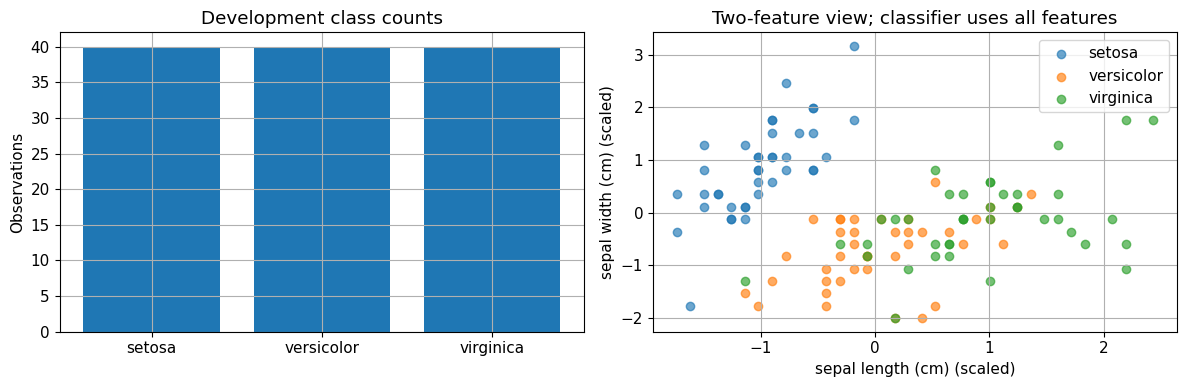

In [18]:
fig,axs=plt.subplots(1,2,figsize=(12,4))
labels,counts=np.unique(y_develop,return_counts=True)
axs[0].bar(project_names[labels],counts);axs[0].set(title='Development class counts',ylabel='Observations')
exploreZ=StandardScaler().fit_transform(X_develop)
for label in labels:
    axs[1].scatter(exploreZ[y_develop==label,0],exploreZ[y_develop==label,1],label=project_names[label],alpha=.65)
axs[1].set(xlabel=str(project_data.feature_names[0])+' (scaled)',ylabel=str(project_data.feature_names[1])+' (scaled)',title='Two-feature view; classifier uses all features')
axs[1].legend();plt.tight_layout();plt.show()

### Implement F · Construct a leakage-safe five-fold search
Return an **unfitted** GridSearchCV with a StandardScaler/SVC pipeline named scale and svc. Use the supplied splitter, accuracy scoring, refit=True, return_train_score=True, n_jobs=1 and error_score='raise'.

In [19]:
def make_project_search(grid,splitter):
    # TODO: construct the pipeline and search.
    return None

In [20]:
candidate_search=make_project_search(project_grid,project_cv)
if candidate_search is None: print('Complete Implement F to construct your own search.')
else:
    assert isinstance(candidate_search,GridSearchCV)
    assert isinstance(candidate_search.estimator,Pipeline)
    assert isinstance(candidate_search.estimator.named_steps['scale'],StandardScaler)
    assert isinstance(candidate_search.estimator.named_steps['svc'],SVC)
    assert candidate_search.cv.n_splits==5 and candidate_search.scoring=='accuracy'
    assert candidate_search.refit and candidate_search.return_train_score
    assert candidate_search.n_jobs==1 and candidate_search.error_score=='raise'
    assert not hasattr(candidate_search,'cv_results_')
    print('Search configuration checks passed.')

Complete Implement F to construct your own search.


**Your reasoning:** write your prediction, observations and explanation here.

### Run the reference workflow, then compare your implementation
This reference is complete so the project can be explored before finishing Implement F. To test your own implementation, replace the reference construction with your function's returned search. The reference supplies the protocol, not your written analysis or conclusions. All tuning uses development data only.

In [21]:
project_pipeline=Pipeline([('scale',StandardScaler()),('svc',SVC(cache_size=200))])
project_search=GridSearchCV(project_pipeline,project_grid,cv=project_cv,scoring='accuracy',
    refit=True,return_train_score=True,n_jobs=1,error_score='raise')
project_search.fit(X_develop,y_develop)
project_results=pd.DataFrame(project_search.cv_results_)
parameter_columns=[column for column in project_results if column.startswith('param_')]
summary_columns=['rank_test_score',*parameter_columns,'mean_train_score','mean_test_score','std_test_score','mean_fit_time']
display(project_results[summary_columns].sort_values('rank_test_score').head(12))
print('Selected parameters:',project_search.best_params_)
print('Selection mean CV accuracy:',project_search.best_score_)
print('Fold spread is descriptive, not an independent-sample confidence interval.')
baseline_scores=cross_val_score(DummyClassifier(strategy='most_frequent'),X_develop,y_develop,cv=project_cv,scoring='accuracy')
print('Majority baseline mean CV accuracy:',baseline_scores.mean())

,rank_test_score,param_svc__C,param_svc__kernel,mean_train_score,mean_test_score,std_test_score,mean_fit_time
4,1,10.000,linear,0.981250,0.975000,0.033333,0.001527
2,2,0.100,linear,0.954167,0.958333,0.045644,0.001652
3,3,1.000,linear,0.979167,0.950000,0.061237,0.001526
1,4,0.010,linear,0.891667,0.883333,0.048591,0.001728
0,4,0.001,linear,0.879167,0.883333,0.061237,0.002385


Selected parameters: {'svc__C': 10, 'svc__kernel': 'linear'}
Selection mean CV accuracy: 0.975
Fold spread is descriptive, not an independent-sample confidence interval.
Majority baseline mean CV accuracy: 0.3333333333333333


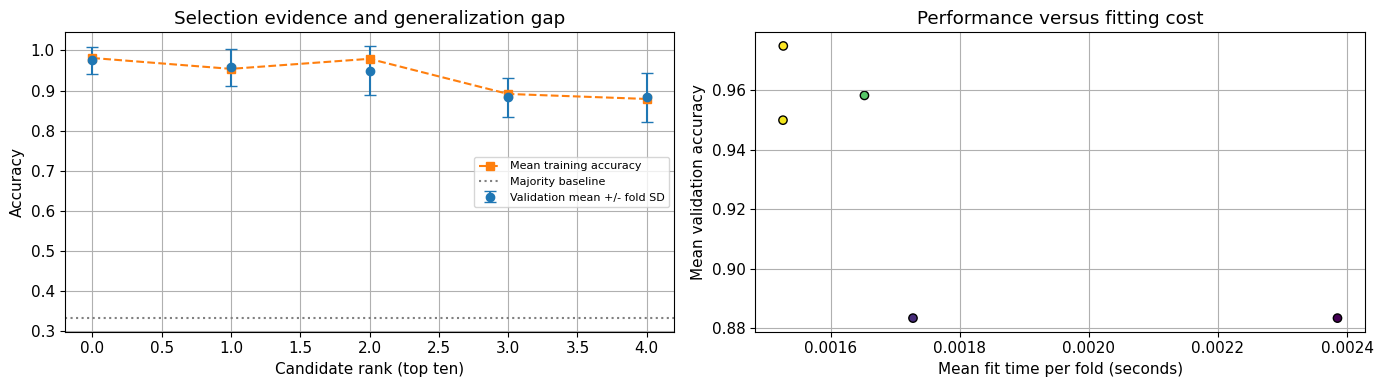

In [22]:
top=project_results.sort_values('rank_test_score').head(10).reset_index(drop=True)
fig,axs=plt.subplots(1,2,figsize=(14,4));x=np.arange(len(top))
axs[0].errorbar(x,top['mean_test_score'],yerr=top['std_test_score'],fmt='o',capsize=4,label='Validation mean +/- fold SD')
axs[0].plot(x,top['mean_train_score'],'s--',label='Mean training accuracy')
axs[0].axhline(baseline_scores.mean(),color='gray',linestyle=':',label='Majority baseline')
axs[0].set(xlabel='Candidate rank (top ten)',ylabel='Accuracy',title='Selection evidence and generalization gap');axs[0].legend(fontsize=8)
axs[1].scatter(project_results['mean_fit_time'],project_results['mean_test_score'],c=project_results['mean_train_score'],cmap='viridis',edgecolors='black')
axs[1].set(xlabel='Mean fit time per fold (seconds)',ylabel='Mean validation accuracy',title='Performance versus fitting cost')
plt.tight_layout();plt.show()

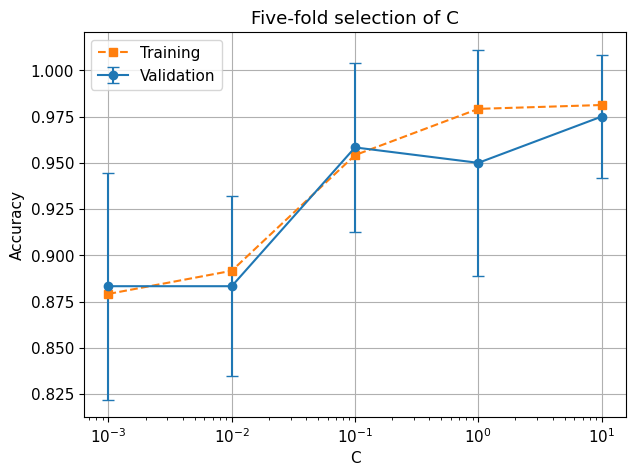

In [23]:
ordered=project_results.sort_values('param_svc__C')
fig,ax=plt.subplots();Cs=np.array(ordered['param_svc__C'],dtype=float)
ax.errorbar(Cs,ordered['mean_test_score'],yerr=ordered['std_test_score'],marker='o',capsize=4,label='Validation')
ax.plot(Cs,ordered['mean_train_score'],'s--',label='Training')
ax.set(xscale='log',xlabel='C',ylabel='Accuracy',title='Five-fold selection of C');ax.legend();plt.show()

### Freeze the choice, then evaluate once on the held-out test set
Write down the selected configuration and expected failure modes before running this cell. Do not alter the grid based on these results. A new hypothesis after seeing test results requires a fresh evaluation plan; the existing test is no longer untouched.

Final test accuracy: 0.9666666666666667
Final test balanced accuracy: 0.9666666666666667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



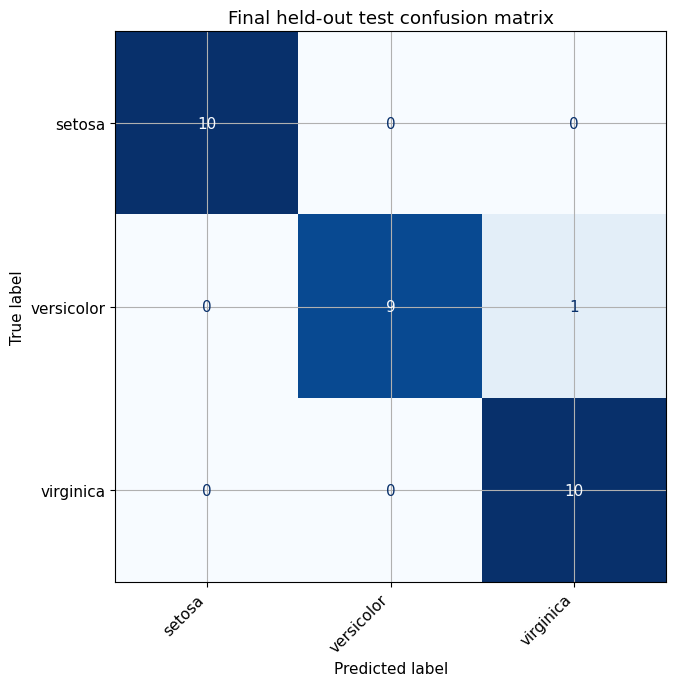

In [24]:
holdout_predictions=project_search.predict(X_holdout)
print('Final test accuracy:',accuracy_score(y_holdout,holdout_predictions))
print('Final test balanced accuracy:',balanced_accuracy_score(y_holdout,holdout_predictions))
print(classification_report(y_holdout,holdout_predictions,target_names=project_names,zero_division=0))
fig,ax=plt.subplots(figsize=(8,7))
ConfusionMatrixDisplay.from_predictions(y_holdout,holdout_predictions,display_labels=project_names,cmap='Blues',ax=ax,colorbar=False)
ax.set_title('Final held-out test confusion matrix');plt.xticks(rotation=45,ha='right');plt.tight_layout();plt.show()

### Implement G · Manual five-fold selection
Implement the inner grid search without calling GridSearchCV or cross_val_score. Use ParameterGrid, clone the pipeline for every fold, fit on training indices and score validation indices. Return (best parameter dictionary, list of candidate mean scores). Keep the first candidate in a tie. This is an independent implementation of the selection protocol.

In [25]:
def manual_grid(estimator,grid,X,y,splitter):
    # TODO: iterate candidates and fold splits; fit fresh clones and average validation scores.
    return None

In [26]:
# A small two-candidate audit; the main project above uses the full stated grid.
audit_grid={'svc__kernel':['linear'],'svc__C':[.1,1]}
audit=manual_grid(project_pipeline,audit_grid,X_develop,y_develop,project_cv)
if audit is None: print('Complete Implement G for the independent selection challenge.')
else:
    reference=GridSearchCV(project_pipeline,audit_grid,cv=project_cv,scoring='accuracy',n_jobs=1,error_score='raise').fit(X_develop,y_develop)
    best_parameters,mean_scores=audit
    np.testing.assert_allclose(mean_scores,reference.cv_results_['mean_test_score'],atol=1e-12)
    assert best_parameters==reference.best_params_
    print('Manual five-fold grid agrees with GridSearchCV:',best_parameters)

Complete Implement G for the independent selection challenge.


**Your reasoning:** write your prediction, observations and explanation here.

### Submit an evidence-based mini-project report
1. Your pre-experiment hypothesis and evaluation protocol.
2. Tuned parameter names, values, candidate count and five-fold fit count. Account separately for baseline and learning-curve fits.
3. Training versus validation performance, descriptive fold spread, model complexity and fit time. Explain why a small CV difference may be inconclusive.
4. A majority-baseline comparison and per-class error analysis.
5. The frozen choice, final test confusion matrix and limitations.
6. A follow-up experiment with its own fresh evaluation plan.

**Independent challenge:** implement manual five-fold grid search with cloned pipelines, the same folds, the same scoring and development-only model selection. Compare with GridSearchCV, documenting tie-breaking, order and seeds. An instructor reference is supplied separately. An optional further project is nested CV: explain the separate roles of inner selection folds and outer evaluation folds.

Your report is evaluated for reasoning and protocol, not for obtaining the highest test accuracy.

## Lecture understanding quiz (15–20 min)

Answer before discussing with classmates. For each answer, add a one-sentence justification and point to the relevant lecture concept.

**Q1. What is the distance from (2,0) to x1-x2-1=0?**  
A: 1; B: 1/sqrt(2); C: sqrt(2); D: 2

**Q2. Multiply w and b by +3. What happens to geometric distances?**  
A: triple; B: divide by 3; C: unchanged; D: become negative

**Q3. For the lecture optimum, what is the full margin width?**  
A: 1/sqrt(2); B: sqrt(2); C: 2; D: 1

**Q4. Why is b absent from the quadratic penalty?**  
Short answer

**Q5. Does canonical normalization find the best boundary orientation?**  
A: yes; B: no

**Q6. Which fourth point in the lecture example has functional margin 2?**  
Short answer

**Q7. What is the smallest L2 perturbation norm needed to reach a linear boundary?**  
Short answer

**Q8. Why can a perceptron and an SVM both have zero training error but different robustness?**  
Short answer

**Q9. Does the bias belong in the norm denominator for point-to-hyperplane distance?**  
A: yes; B: no

**Q10. For a linear SVC, how many hyperparameters are varied by a grid over C alone?**  
Short answer

In [27]:
# Record your answers; this cell does not grade or reveal the key.
quiz_answers = {'Q1': '', 'Q2': '', 'Q3': '', 'Q4': '', 'Q5': '', 'Q6': '', 'Q7': '', 'Q8': '', 'Q9': '', 'Q10': ''}
quiz_justifications = {}
display(quiz_answers)

{'Q1': '',
 'Q2': '',
 'Q3': '',
 'Q4': '',
 'Q5': '',
 'Q6': '',
 'Q7': '',
 'Q8': '',
 'Q9': '',
 'Q10': ''}

## Exit ticket
In 3–5 sentences: what did your experiment show, how does the equation explain it, and what question remains? Save the notebook with your completed code, plots, quiz responses and explanations.